In [1]:
import pandas as pd

# Load your dataset
df = pd.read_csv("train-2025.csv", dtype={6: "string"})

In [2]:
df.head()

,Unnamed: 0,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,...,inc_extraord,taxes,profit,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations
0,17,520288,2011-12-31,28.0,SRL,14.0,<NA>,2011,67537.0,1137566.0,...,-309.0,-80959.0,-81288.0,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0
1,18,520288,2008-12-31,28.0,SRL,14.0,<NA>,2008,256438.0,1181416.0,...,-678.0,-94622.0,-107382.0,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0
2,19,520288,2009-12-31,28.0,SRL,14.0,<NA>,2009,194046.0,1152014.0,...,4224.0,-74235.0,-77819.0,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0
3,21,520288,2012-12-31,28.0,SRL,14.0,<NA>,2012,15195.0,1116938.0,...,3634.0,-250786.0,-250786.0,NaN,-161478.0,-12.99,NaN,367892.0,-1094962.0,-168907.0
4,22,520288,2007-12-31,28.0,SRL,14.0,<NA>,2007,126603.0,1127807.0,...,820.0,92192.0,36733.0,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0


**Creating Default Flag**

In [3]:
import pandas as pd
import numpy as np

# 1. Ensure dates are in datetime format
df['stmt_date'] = pd.to_datetime(df['stmt_date'])
df['def_date'] = pd.to_datetime(df['def_date'])   # will be NaT for non-defaulters

# 2. Choose a reporting lag (here: 4 months ≈ "April/May", following the book)
reporting_lag = pd.DateOffset(months=4)

# 3. Compute the date when the financials are realistically available
df['info_date'] = df['stmt_date'] + reporting_lag

# 4. Given information as of info_year, will the firm default in the next 12 months?
df['info_year'] = df['info_date'].dt.year

# 5. Define the end of the 1-year prediction horizon
df['horizon_end'] = df['info_date'] + pd.DateOffset(years=1)

# 6. Create the default flag:
#    1 if default occurs between info_date (inclusive) and horizon_end (exclusive), else 0.
df['default_flag'] = np.where(
    df['def_date'].notna()
    & (df['def_date'] >= df['info_date'])
    & (df['def_date'] < df['horizon_end']),
    1,
    0
).astype(int)

**Imputing Values**

In [4]:
# Drop col:eqty_corp_family_tot
df.drop(columns=['eqty_corp_family_tot'], inplace=True)

cols_to_check = [
    "rev_operating",
    "COGS",
    "prof_operations",
    "cash_and_equiv",
    "roe"
]

# Store missing counts BEFORE imputation
missing_before = df[cols_to_check].isna().sum()

# 1. Fill missing rev_operating
mask_rev_missing = (
    df["rev_operating"].isna() &
    df["COGS"].notna() &
    df["prof_operations"].notna()
)

df.loc[mask_rev_missing, "rev_operating"] = (
    df.loc[mask_rev_missing, "COGS"] + df.loc[mask_rev_missing, "prof_operations"]
)


# 2. Fill missing COGS
mask_cogs_missing = (
    df["COGS"].isna() &
    df["rev_operating"].notna() &
    df["prof_operations"].notna()
)

df.loc[mask_cogs_missing, "COGS"] = (
    df.loc[mask_cogs_missing, "rev_operating"] - df.loc[mask_cogs_missing, "prof_operations"]
)


# 3. Fill missing prof_operations
mask_prof_missing = (
    df["prof_operations"].isna() &
    df["rev_operating"].notna() &
    df["COGS"].notna()
)

df.loc[mask_prof_missing, "prof_operations"] = (
    df.loc[mask_prof_missing, "rev_operating"] - df.loc[mask_prof_missing, "COGS"]
)


# Fill missing cash_and_equiv = asst_current - AR (only where both are available)
mask = df["cash_and_equiv"].isna() & df["asst_current"].notna() & df["AR"].notna()

df.loc[mask, "cash_and_equiv"] = df.loc[mask, "asst_current"] - df.loc[mask, "AR"]


mask_roe = (
    df["roe"].isna() &                            # Only if ROE is missing
    df["profit"].notna() &                        # Profit available
    df["eqty_tot"].notna() &                      # Equity available
    ~((df["profit"] < 0) & (df["eqty_tot"] < 0))  # Exclude both negative
)

# Calculate ROE = (profit / eqty_tot) * 100 only for valid cases
df.loc[mask_roe, "roe"] = (
    (df.loc[mask_roe, "profit"] / df.loc[mask_roe, "eqty_tot"]) * 100
).round(2)

# Store missing counts AFTER imputation
missing_after = df[cols_to_check].isna().sum()

# Compare
print("\nMissing values before imputation:")
print(missing_before)

print("\nMissing values after imputation:")
print(missing_after)


Missing values before imputation:
rev_operating        174
COGS                  24
prof_operations       21
cash_and_equiv        17
roe                72937
dtype: int64

Missing values after imputation:
rev_operating         21
COGS                  21
prof_operations       21
cash_and_equiv        12
roe                38649
dtype: int64


**Generating Leverage Ratios**

In [5]:
# Total Liabilities = Total Assets - Total Equity
df["liab_tot"] = df["asst_tot"] - df["eqty_tot"]

# Debt-to-Equity Ratio RAW
df["debt_to_equity_raw"] = df["liab_tot"] / df["eqty_tot"]

# Debt Ratio RAW
df["debt_ratio_raw"] = df["liab_tot"] / df["asst_tot"]

# Equity Ratio Raw
df["equity_ratio_raw"] = df["eqty_tot"] / df["asst_tot"]

ratio_cols = [
    "debt_to_equity_raw",
    "debt_ratio_raw",
    "equity_ratio_raw"
]

print("Missing Values:")
df[ratio_cols].isna().sum()

Missing Values:


debt_to_equity_raw    1
debt_ratio_raw        1
equity_ratio_raw      1
dtype: int64

**Generating Profitability Ratios**

In [6]:
# Gross Margin = (rev_operating - COGS) / rev_operating
df["gross_margin_raw"] = (df["rev_operating"] - df["COGS"]) / df["rev_operating"]

# Operating Margin = prof_operations / rev_operating
df["operating_margin_raw"] = df["prof_operations"] / df["rev_operating"]

# Return on Assets (ROA) = prof_operations / asst_tot
df["roa_raw"] = df["prof_operations"] / df["asst_tot"]

# Return on Equity (ROE)
df.rename(columns={"roe": "roe_raw"}, inplace=True)

# (Optional) Check NaNs in ratios
ratio_cols = [
    "gross_margin_raw",
    "operating_margin_raw",
    "roa_raw",
    "roe_raw"
]

print("Missing Values:")
df[ratio_cols].isna().sum()

Missing Values:


gross_margin_raw          620
operating_margin_raw      620
roa_raw                    21
roe_raw                 38649
dtype: int64

**Generating Efficiency Ratios**

In [7]:
# Compute Asset Turnover ratio
df['asst_turnover_ratio_raw'] = df['rev_operating'] / df['asst_tot']

# (Optional) Check NaNs in ratios
ratio_cols = [
    "asst_turnover_ratio_raw"
]

print("Missing Values:")
df[ratio_cols].isna().sum()

Missing Values:


asst_turnover_ratio_raw    21
dtype: int64

**Generating Liquidity Ratios**

In [8]:
# Current Ratio
df["current_ratio_raw"] = df["asst_current"] / df["debt_st"]

# Cash Ratio
df["cash_ratio_raw"] = df["cash_and_equiv"] / df["debt_st"]

# (Optional) Check NaNs in ratios
ratio_cols = [
    "current_ratio_raw",
    "cash_ratio_raw",
]

print("Missing Values:")
df[ratio_cols].isna().sum()

Missing Values:


current_ratio_raw     27
cash_ratio_raw       122
dtype: int64

**Generating Coverage Ratios**

In [9]:
# Compute Asset Coverage Ratio
df["asst_coverage_ratio_raw"] = (
    (df["asst_tot"] - df["asst_intang_fixed"] - df["debt_st"]) /
    (df["debt_st"] + df["debt_lt"])
)

# (Optional) Check NaNs in ratios
ratio_cols = [
    "asst_coverage_ratio_raw",
]

print("Missing Values:")
df[ratio_cols].isna().sum()

Missing Values:


asst_coverage_ratio_raw    278
dtype: int64

**Computing Size Variiable**

In [10]:
# Size = Total Assets
df['log_asst_tot'] = np.log1p(df['asst_tot'].clip(lower=0))

**Adding Missing Flag (Raw Ratios)**

In [11]:
# Identify Ratio Columns
raw_ratio_cols = [col for col in df.columns if col.endswith("_raw")]

for col in raw_ratio_cols:
    df[col + "_missing"] = df[col].isna().astype(int)


missing_flag_cols = [col for col in df.columns if col.endswith("_missing")]

print("Raw ratios:")
for col in raw_ratio_cols:
    print(" -", col)

print("\nMissing flags:")
for col in missing_flag_cols:
    print(" -", col)

Raw ratios:
 - roe_raw
 - debt_to_equity_raw
 - debt_ratio_raw
 - equity_ratio_raw
 - gross_margin_raw
 - operating_margin_raw
 - roa_raw
 - asst_turnover_ratio_raw
 - current_ratio_raw
 - cash_ratio_raw
 - asst_coverage_ratio_raw

Missing flags:
 - roe_raw_missing
 - debt_to_equity_raw_missing
 - debt_ratio_raw_missing
 - equity_ratio_raw_missing
 - gross_margin_raw_missing
 - operating_margin_raw_missing
 - roa_raw_missing
 - asst_turnover_ratio_raw_missing
 - current_ratio_raw_missing
 - cash_ratio_raw_missing
 - asst_coverage_ratio_raw_missing


**Checking Correlation (Raw Ratios)**

In [12]:
# Calculating correlation
raw_corr = df[raw_ratio_cols].corr()
raw_corr

# Display results
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Correlation Matrix:")
print(raw_corr.to_string())

Correlation Matrix:
                              roe_raw  debt_to_equity_raw  debt_ratio_raw  equity_ratio_raw  gross_margin_raw  operating_margin_raw       roa_raw  asst_turnover_ratio_raw  current_ratio_raw  cash_ratio_raw  asst_coverage_ratio_raw
roe_raw                  1.000000e+00       -8.727212e-01       -0.001607          0.001607          0.000002              0.000002  2.266384e-04                 0.000108           0.000004        0.000004            -3.185320e-07
debt_to_equity_raw      -8.727212e-01        1.000000e+00        0.001642         -0.001642          0.000028              0.000028 -5.781129e-07                -0.000062           0.000043       -0.000010             9.297468e-07
debt_ratio_raw          -1.606922e-03        1.641928e-03        1.000000         -1.000000          0.001628              0.001628 -1.059847e-02                 0.065294           0.000005       -0.001782             5.777656e-04
equity_ratio_raw         1.606922e-03       -1.641928e-0

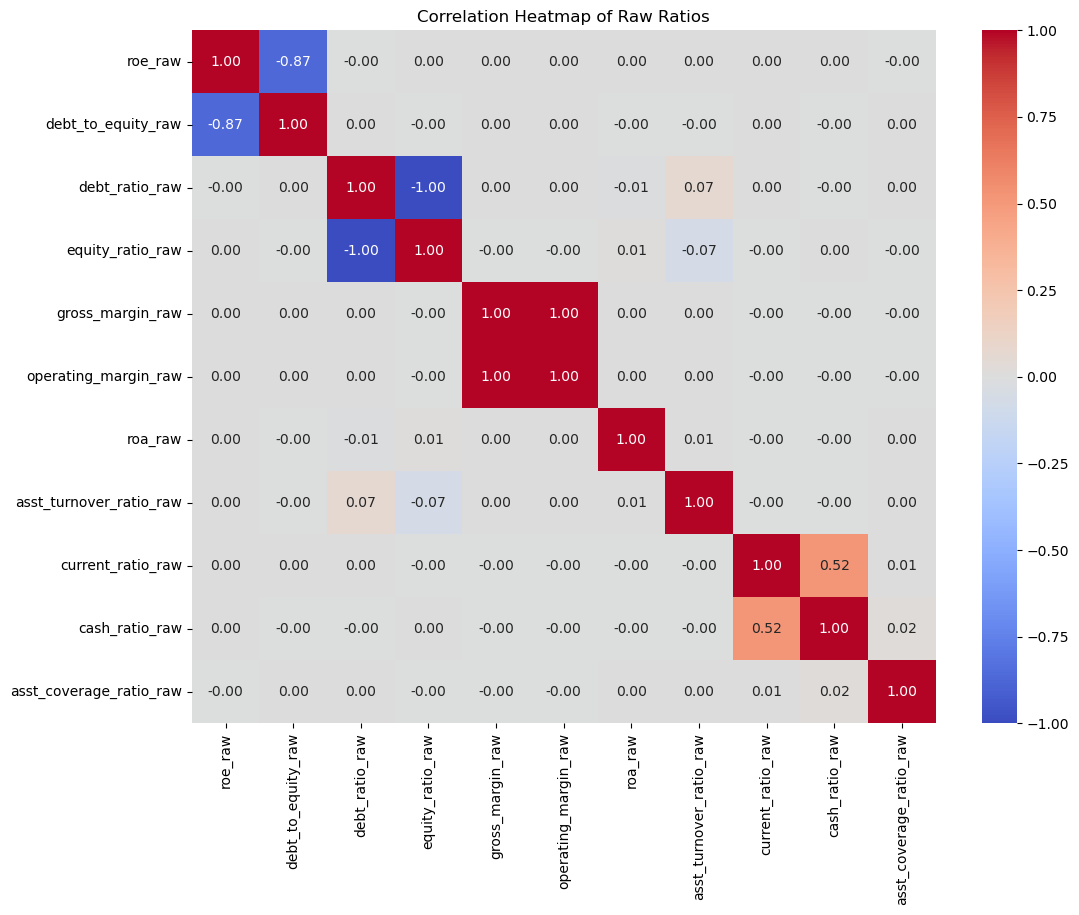

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
sns.heatmap(raw_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Raw Ratios")
plt.show()

In [14]:
# Calculating Variance Inflation Factor
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Prepare data
X_for_vif = df[raw_ratio_cols].replace([np.inf, -np.inf], np.nan)
X_for_vif = X_for_vif.dropna()

# Compute VIF
vif_df = pd.DataFrame()
vif_df["feature"] = X_for_vif.columns
vif_df["VIF"] = [
    variance_inflation_factor(X_for_vif.values, i)
    for i in range(len(X_for_vif.columns))
]

# Sort in ascending order (best → worst multicollinearity)
vif_df = vif_df.sort_values(by="VIF", ascending=True).reset_index(drop=True)

vif_df

,feature,VIF
0,roa_raw,1.000067e+00
1,asst_coverage_ratio_raw,1.003700e+00
2,asst_turnover_ratio_raw,1.008649e+00
3,equity_ratio_raw,1.235880e+00
4,current_ratio_raw,1.394988e+00
5,cash_ratio_raw,1.399238e+00
6,debt_ratio_raw,1.465635e+00
7,roe_raw,4.297204e+00
8,debt_to_equity_raw,4.297698e+00
9,gross_margin_raw,3.602880e+14


In [15]:
# Columns to drop due to high correlation
cols_to_drop = [
    "debt_to_equity_raw",
    "gross_margin_raw",
    "equity_ratio_raw",
    "equity_ratio_raw_missing",
    "gross_margin_raw_missing",
    "equity_ratio_raw_missing"
]

df = df.drop(columns=cols_to_drop, errors="ignore")

In [16]:
df.head()

,Unnamed: 0,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,eqty_tot,liab_lt,liab_lt_emp,debt_bank_st,debt_bank_lt,debt_fin_st,debt_fin_lt,AP_st,AP_lt,debt_st,debt_lt,rev_operating,COGS,prof_operations,goodwill,inc_financing,exp_financing,prof_financing,inc_extraord,taxes,profit,days_rec,ebitda,roa,roe_raw,wc_net,margin_fin,cf_operations,info_date,info_year,horizon_end,default_flag,liab_tot,debt_ratio_raw,operating_margin_raw,roa_raw,asst_turnover_ratio_raw,current_ratio_raw,cash_ratio_raw,asst_coverage_ratio_raw,log_asst_tot,roe_raw_missing,debt_to_equity_raw_missing,debt_ratio_raw_missing,operating_margin_raw_missing,roa_raw_missing,asst_turnover_ratio_raw_missing,current_ratio_raw_missing,cash_ratio_raw_missing,asst_coverage_ratio_raw_missing
0,17,520288,2011-12-31,28.0,SRL,14.0,NaT,2011,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,289982.0,0.0,77653.0,24328.0,473281.0,0.0,0.0,170808.0,0.0,237238.0,1340801.0,538081.0,612202.0,-74121.0,157436.0,-6529.0,15550.0,0.0,-309.0,-80959.0,-81288.0,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0,2012-04-30,2012,2013-04-30,0,1656958.0,0.851058,-0.137751,-0.038071,0.276373,3.091815,0.008780,1.040637,14.481770,0,0,0,0,0,0,0,0,0
1,18,520288,2008-12-31,28.0,SRL,14.0,NaT,2008,256438.0,1181416.0,860.0,622992.0,387653.0,5339.0,2077346.0,-37325.0,0.0,64832.0,184518.0,548543.0,0.0,0.0,111047.0,0.0,525040.0,1521607.0,967389.0,1024802.0,-57413.0,253845.0,-36531.0,49758.0,0.0,-678.0,-94622.0,-107382.0,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0,2009-04-30,2009,2010-04-30,0,2114671.0,1.017968,-0.059348,-0.027638,0.465685,1.186561,0.010169,0.633166,14.546602,1,0,0,0,0,0,0,0,0
2,19,520288,2009-12-31,28.0,SRL,14.0,NaT,2009,194046.0,1152014.0,860.0,615252.0,388260.0,10492.0,1975874.0,-45139.0,0.0,67962.0,173526.0,550291.0,0.0,0.0,92699.0,0.0,825923.0,1125755.0,638687.0,681513.0,-42826.0,238817.0,-35633.0,35239.0,0.0,4224.0,-74235.0,-77819.0,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0,2010-04-30,2010,2011-04-30,0,2021013.0,1.022845,-0.067053,-0.021674,0.323243,0.744927,0.012703,0.489786,14.496522,1,0,0,0,0,0,0,0,0
3,21,520288,2012-12-31,28.0,SRL,14.0,NaT,2012,15195.0,1116938.0,2023.0,734000.0,287852.0,6548.0,1872882.0,39194.0,0.0,88825.0,66941.0,399907.0,0.0,0.0,252349.0,0.0,366108.0,1377427.0,319790.0,563147.0,-243357.0,-32223.0,-11063.0,14057.0,0.0,3634.0,-250786.0,-250786.0,NaN,-161478.0,-12.99,-639.86,367892.0,-1094962.0,-168907.0,2013-04-30,2013,2014-04-30,0,1833688.0,0.979073,-0.760990,-0.129937,0.170748,2.004873,0.017885,0.855491,14.442990,0,0,0,0,0,0,0,0,0
4,22,520288,2007-12-31,28.0,SRL,14.0,NaT,2007,126603.0,1127807.0,620.0,484753.0,455224.0,14279.0,1769122.0,70060.0,0.0,64909.0,522502.0,124241.0,851.0,0.0,108895.0,0.0,801760.0,832305.0,2041155.0,1931401.0,109754.0,363557.0,-18382.0,13569.0,0.0,820.0,92192.0,36733.0,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0,2008-04-30,2008,2009-04-30,0,1699062.0,0.960398,0.053771,0.062039,1.153767,0.604611,0.017810,0.514520,14.385995,0,0,0,0,0,0,0,0,0


**Selecting Final Raw Ratios**

In [17]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.stats import ks_2samp

In [18]:
# Final raw ratios
final_raw_ratios = [
    "current_ratio_raw",
    'cash_ratio_raw',
    "debt_ratio_raw",
    "operating_margin_raw",
    "roa_raw",
    "roe_raw",
    "asst_turnover_ratio_raw",
    "asst_coverage_ratio_raw"
]

# Missing flags for those ratios
final_missing_flags = [c + "_missing" for c in final_raw_ratios]

**Non-Parametric Function**

In [19]:
import numpy as np
import pandas as pd
from copy import deepcopy


def fit_nonparametric_transform(df, x_col, y_col="default_flag", k=100):
    """
    Fit a nonparametric transform for one variable:
    - bin by quantiles
    - estimate default rate per bin
    - store edges + quantile locations for later interpolation

    Returns a dict with:
        "edges": bin boundaries in x,
        "quantiles": quantile positions for each edge,
        "pd_per_bin": default rate per bin
    """
    data = df[[x_col, y_col]].dropna().copy()
    x = data[x_col].values
    y = data[y_col].astype(float).values

    # Quantile positions (0..1)
    quantiles = np.linspace(0.0, 1.0, k + 1)

    # Quantile edges of x
    edges = np.quantile(x, quantiles)

    # Remove duplicate edges (can happen if many identical x values)
    edges, unique_idx = np.unique(edges, return_index=True)
    quantiles = quantiles[unique_idx]

    if len(edges) < 2:
        raise ValueError(f"Not enough unique values for transform of {x_col}")

    # Assign each observation to a bin based on edges
    bin_idx = np.searchsorted(edges, x, side="right") - 1
    bin_idx = np.clip(bin_idx, 0, len(edges) - 2)
    data["bin"] = bin_idx

    # Default rate per bin; ensure we have one value for every bin
    grouped = data.groupby("bin")[y_col].mean()
    grouped = grouped.reindex(range(len(edges) - 1))
    # If any bin is empty, fill from neighbours
    grouped = grouped.fillna(method="ffill").fillna(method="bfill")
    pd_per_bin = grouped.values  # shape: (num_bins,)

    return {
        "edges": edges,          # bin boundaries in x
        "quantiles": quantiles,  # quantile positions for edges
        "pd_per_bin": pd_per_bin # default rate for each bin (between edges[i], edges[i+1])
    }


def apply_nonparametric_transform(x_series, transform):
    """
    Apply the fitted nonparametric transform with interpolation.

    x_series: pandas Series of the raw ratio (can contain NaNs).
    Returns a Series of transformed PD values (NaNs preserved where x is NaN).
    """
    edges = transform["edges"]
    quantiles = transform["quantiles"]
    pd_bins = transform["pd_per_bin"]

    x = x_series.values
    result = np.full_like(x, np.nan, dtype=float)

    # Mask for non-missing x
    non_missing = ~np.isnan(x)
    if not np.any(non_missing):
        # All missing: just return all-NaN series
        return pd.Series(result, index=x_series.index)

    x_nm = x[non_missing]

    # Find bins for non-missing x
    bin_idx = np.searchsorted(edges, x_nm, side="right") - 1
    bin_idx = np.clip(bin_idx, 0, len(edges) - 2)

    b_i = edges[bin_idx]
    b_ip1 = edges[bin_idx + 1]
    q_i = quantiles[bin_idx]
    q_ip1 = quantiles[bin_idx + 1]

    # Interpolation factor inside bin
    denom = (b_ip1 - b_i)
    t = np.zeros_like(x_nm, dtype=float)
    mask = denom > 0
    t[mask] = (x_nm[mask] - b_i[mask]) / denom[mask]
    t = np.clip(t, 0.0, 1.0)

    # Interpolated quantile position q*
    q_star = q_i + t * (q_ip1 - q_i)

    # PD is defined per bin; put them at mid-quantiles for interpolation
    q_mid = (quantiles[:-1] + quantiles[1:]) / 2.0  # one per bin, same length as pd_bins

    pd_vals_nm = np.interp(
        q_star,
        q_mid,
        pd_bins,
        left=pd_bins[0],
        right=pd_bins[-1],
    )

    # Fill result only for non-missing entries
    result[non_missing] = pd_vals_nm

    return pd.Series(result, index=x_series.index)

In [20]:
def fit_all_transforms(train_df, raw_ratio_cols, y_col="default_flag", k=100):
    """
    Fit nonparametric transforms for all variables in raw_ratio_cols on the TRAIN data.
    """
    transforms = {}
    for col in raw_ratio_cols:
        transforms[col] = fit_nonparametric_transform(
            train_df,
            x_col=col,
            y_col=y_col,
            k=k,
        )
    return transforms


def transform_train(train_df, raw_ratio_cols, transforms, suffix="_tr"):
    """
    Apply transforms to TRAIN data and compute mean T(x) per variable.

    - NaNs in raw ratios become NaNs in transformed ratios
    - You already have raw missing flags; we just impute transformed NaNs
      with mean T(x) (computed on train).

    Returns:
        df_tr  : transformed train dataframe (with *_tr columns)
        mean_tr: dict mapping raw col -> mean transformed value T(x) on train
    """
    df_tr = deepcopy(train_df)
    mean_tr = {}

    for col in raw_ratio_cols:
        tr_col = col.replace("_raw", "") + suffix
        # Transform (NaNs preserved)
        df_tr[tr_col] = apply_nonparametric_transform(df_tr[col], transforms[col])

        # Mean of non-missing transformed values T(x)
        mean_val = df_tr[tr_col].mean(skipna=True)
        mean_tr[col] = mean_val

        # Impute transformed NaNs with this mean
        df_tr[tr_col] = df_tr[tr_col].fillna(mean_val)

    return df_tr, mean_tr


def transform_test(test_df, raw_ratio_cols, transforms, mean_tr, suffix="_tr"):
    """
    Apply transforms to TEST (or validation) data.

    - Uses the transforms fitted on TRAIN.
    - NaNs in raw ratios become NaNs in transformed ratios.
    - Transformed NaNs are imputed with the TRAIN mean T(x) for that variable.

    Returns:
        df_tr: transformed test dataframe (with *_tr columns)
    """
    df_tr = deepcopy(test_df)

    for col in raw_ratio_cols:
        tr_col = col.replace("_raw", "") + suffix
        df_tr[tr_col] = apply_nonparametric_transform(df_tr[col], transforms[col])

        # Impute with TRAIN mean T(x)
        df_tr[tr_col] = df_tr[tr_col].fillna(mean_tr[col])

    return df_tr

**KS Statistic**

In [21]:
def ks_statistic(y_true, y_pred):
    return ks_2samp(y_pred[y_true == 1], y_pred[y_true == 0]).statistic

**K-Fold Cross Validation**

In [22]:
from sklearn.model_selection import KFold, GridSearchCV

def perform_kfold_lr(train_df, feature_cols, target_col="default_flag"):
    X_train = train_df[feature_cols].values
    y_train = train_df[target_col].values

    lr = LogisticRegression(max_iter=5000, solver="lbfgs")
    param_grid = {"C": [0.01, 0.1, 1, 10]}

    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(lr, param_grid, cv=kfold, scoring="roc_auc")
    grid.fit(X_train, y_train)

    return grid.best_estimator_, grid.best_params_

**Function - Training Final Model**

In [23]:
def train_final_lr(train_df, best_params, feature_cols):
    X_train = train_df[feature_cols].values
    y_train = train_df["default_flag"].values

    lr = LogisticRegression(max_iter=5000, solver="lbfgs", **best_params)
    lr.fit(X_train, y_train)
    return lr

**Function - Evaluating Model**

In [24]:
def evaluate_test_year(model, test_df, feature_cols):
    X_test = test_df[feature_cols].values
    y_test = test_df["default_flag"].values

    preds = model.predict_proba(X_test)[:, 1]

    return {
        "preds": preds,
        "auc": roc_auc_score(y_test, preds),
        "ks": ks_statistic(y_test, preds),
        "brier": brier_score_loss(y_test, preds)
    }

**Walk Forward Analysis**

In [27]:
# Defining windows for analysis
walk_windows = [
    {"train_years": [2007], "test_year": 2008},
    {"train_years": [2007, 2008], "test_year": 2009},
    {"train_years": [2007, 2008, 2009], "test_year": 2010},
    {"train_years": [2007, 2008, 2009, 2010], "test_year": 2011},
    {"train_years": [2007, 2008, 2009, 2010, 2011], "test_year": 2012},
]

In [28]:
# WFA
results = []
all_preds = []

for window in walk_windows:

    train_df = df[df["fs_year"].isin(window["train_years"])].copy()
    test_df  = df[df["fs_year"] == window["test_year"]].copy()

    print(f"\n===== Train {window['train_years']} → Test {window['test_year']} =====")

    # 1. Fit T(x) on TRAIN
    transforms = fit_all_transforms(train_df, final_raw_ratios)

    # 2. Apply transforms
    train_tr, mean_tr = transform_train(train_df, final_raw_ratios, transforms)
    test_tr = transform_test(test_df, final_raw_ratios, transforms, mean_tr)

    # 3. Features
    transformed_cols = [c.replace("_raw", "") + "_tr" for c in final_raw_ratios]
    feature_cols = transformed_cols + final_missing_flags + ["log_asst_tot"]

    # 4. K-fold hyperparameter tuning
    best_model, best_params = perform_kfold_lr(train_tr, feature_cols)
    print("Best params:", best_params)

    # 5. Train final model
    final_model = train_final_lr(train_tr, best_params, feature_cols)

    # 6. Evaluate on test window
    eval_res = evaluate_test_year(final_model, test_tr, feature_cols)
    eval_res["test_year"] = window["test_year"]
    results.append(eval_res)

    print(f"AUC: {eval_res['auc']:.3f}, KS: {eval_res['ks']:.3f}, Brier: {eval_res['brier']:.3f}")

    # Save test predictions
    tmp = test_tr[["id", "fs_year", "default_flag"]].copy()
    tmp["pd_pred"] = eval_res["preds"]
    all_preds.append(tmp)


===== Train [2007] → Test 2008 =====


/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4529: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4529: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/adityataware/anaconda3/lib/python3.10/site-packag

Best params: {'C': 10}
AUC: 0.804, KS: 0.455, Brier: 0.010

===== Train [2007, 2008] → Test 2009 =====


/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4529: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


Best params: {'C': 1}
AUC: 0.806, KS: 0.455, Brier: 0.014

===== Train [2007, 2008, 2009] → Test 2010 =====


...

Best params: {'C': 1}
AUC: 0.789, KS: 0.428, Brier: 0.015

===== Train [2007, 2008, 2009, 2010] → Test 2011 =====


/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


Best params: {'C': 1}
AUC: 0.799, KS: 0.470, Brier: 0.012

===== Train [2007, 2008, 2009, 2010, 2011] → Test 2012 =====


/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


Best params: {'C': 0.1}
AUC: 0.917, KS: 0.700, Brier: 0.002


**Training Final Model**

In [30]:
final_train_df = df[df["fs_year"] <= 2011].copy()

transforms_full = fit_all_transforms(final_train_df, final_raw_ratios)
final_train_tr, final_mean_tr = transform_train(final_train_df, final_raw_ratios, transforms_full)

transformed_cols = [c.replace("_raw", "") + "_tr" for c in final_raw_ratios]
feature_cols_full = transformed_cols + final_missing_flags + ["log_asst_tot"]

X_full = final_train_tr[feature_cols_full].values
y_full = final_train_tr["default_flag"].values

final_prod_model = LogisticRegression(max_iter=5000, solver="lbfgs", C=0.1)
final_prod_model.fit(X_full, y_full)

/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/adityataware/anaconda3/lib/python3.10/site-packages/numpy/lib/function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


LogisticRegression(C=0.1, max_iter=5000)

In [31]:
test_2012 = df[df["fs_year"] == 2012].copy()
test_2012_tr = transform_test(test_2012, final_raw_ratios, transforms_full, final_mean_tr)

X_2012 = test_2012_tr[feature_cols_full].values
y_2012 = test_2012_tr["default_flag"].values

pd_2012 = final_prod_model.predict_proba(X_2012)[:, 1]

auc_2012 = roc_auc_score(y_2012, pd_2012)
ks_2012  = ks_statistic(y_2012, pd_2012)
brier_2012 = brier_score_loss(y_2012, pd_2012)

print("\n====== FINAL HOLDOUT YEAR: 2012 ======")
print("AUC   :", auc_2012)
print("KS    :", ks_2012)
print("Brier :", brier_2012)


====== FINAL HOLDOUT YEAR: 2012 ======
AUC   : 0.9171178909537774
KS    : 0.7003953635332865
Brier : 0.001960315589906651


In [32]:
test_2012_out = test_2012_tr.copy()
test_2012_out["pd_pred"] = pd_2012

# Keep only useful columns
test_2012_out = test_2012_out[["id", "fs_year", "default_flag", "pd_pred"]]

In [33]:
test_2012_out.to_csv("PD_predictions_2012.csv", index=False)
test_2012_out_sorted = test_2012_out.sort_values("pd_pred", ascending=False)
test_2012_out_sorted.head()

,id,fs_year,default_flag,pd_pred
852103,7187620963,2012,0,0.436975
1002301,1714890033,2012,0,0.426342
1007959,3365560659,2012,0,0.424552
880353,8270911004,2012,0,0.423568
863615,7614180961,2012,0,0.423423
